In [ ]:
!pip install matplotlib jupyter-black scikit-learn

In [1]:
import gzip
import json
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
from parquetranger import TableRepo
from shackleton import TableShack
from tqdm.notebook import tqdm

from ccl_science_data.common import (
    IDC,
    PARID,
    PUBY,
    EntC,
    iter_dfs,
    parse_id,
    oa_persistent
)
from common import export_dir, step0_dir, step1_dir, step2_dir

loading  /home/borza/science-data/.env
OA_ROOT:  /mnt/hdd/shared/openalex-parsed
SNAP_ROOT:  /mnt/hdd/shared/openalex-snapshot-2024-10


In [2]:
import jupyter_black

jupyter_black.load()

In [4]:
# https://direct.mit.edu/qss/article/1/1/183/15573/Practical-method-to-reclassify-Web-of-Science

In [3]:
icols = ["Print-ISSN", "E-ISSN"]

exdf = pd.read_excel("ext_list_May_2024.xlsx", sheet_name=None)
df = exdf["Scopus Sources May 2024"]

num_map = {e.split("\n")[1].strip(): e.split("\n")[0].strip() for e in df.columns[-27:]}

issn_to_cat = (
    pd.concat(
        df.dropna(subset=ic)
        .set_index(ic)
        .iloc[:, -32:]
        .loc[:, lambda df: ~df.columns.str.startswith("Top level")]
        for ic in icols
    )
    .melt(ignore_index=False)
    .dropna()["value"]
    .str.split("; ", expand=True)
    .melt(ignore_index=False)["value"]
    .dropna()
    .str.strip()
    .replace(num_map)
    .reset_index()
    .drop_duplicates()
)

In [10]:
to_oas_df = (
    pd.concat(iter_dfs(EntC.SOURCES))
    .assign(id=lambda df: df[IDC].pipe(parse_id))
    .set_index(IDC)["issn"]
    .dropna()
    .apply(json.loads)
    .explode()
    .str.replace("-", "")
    .reset_index()
)

In [11]:
to_oa_full = (
    to_oas_df.merge(issn_to_cat.rename(columns={"index": "issn"}))
    .drop("issn", axis=1)
    .drop_duplicates()
)

In [14]:
pl_piv = pl.from_pandas(
    to_oa_full.assign(c=1)
    .pivot_table(index="id", columns="value", aggfunc="any", values="c")
    .fillna(0)
    .astype(bool)
    .reset_index()
)

In [15]:
pl_w_piv = (
    pl.concat(
        w2s.dropna()
        .apply(parse_id)
        .rename(columns={"source": "id"})
        .pipe(pl.from_pandas)
        .join(pl_piv, on="id")
        .drop("id")
        .unique()
        for w2s in tqdm(iter_dfs(EntC.WORKS, "locations", cols=["source", PARID]))
    )
    .group_by(PARID)
    .max()
    .sort(PARID)
)

0it [00:00, ?it/s]

In [16]:
pl_w_piv.shape

(67002407, 334)

In [17]:
REFID = "referenced_work_id"

In [18]:
#ccols = [e for e in sorted(issn_to_cat["value"].unique()) if e != "3615"]
ccols = pl_w_piv.columns[1:]

In [20]:
idh = "id_hash"

In [23]:
parent_dir = oa_persistent / "categories-tmp"

In [24]:
ref_repo = TableRepo(parent_dir / "ia-refs-repo", group_cols=[idh], max_records=30_000)

In [25]:
# ref_repo.purge()

In [28]:
def add_hash(df, col=PARID):
    return df.with_columns((pl.col(col).alias(idh) % 32).cast(pl.UInt8))

In [26]:
for refdf in tqdm(iter_dfs(EntC.WORKS, "referenced_works")):
    ref_repo.extend(
        refdf.apply(parse_id)
        .pipe(pl.from_pandas)
        .join(pl_w_piv.rename({PARID: REFID}), on=REFID)
        .group_by(PARID)
        .agg(
            [pl.col(c).cast(pl.Float32).sum() for c in ccols]
            + [pl.col(PARID).alias("count").count()]
        )
        .pipe(add_hash)
        .to_pandas()
    )

0it [00:00, ?it/s]

In [27]:
size = 1_000_000

In [94]:
for part, l0_df in tqdm(pl_w_piv.pipe(add_hash).group_by(idh)):
    gz_file = step0_dir / "{:03d}.csv.gz".format(part[0])
    gz_file.unlink(missing_ok=True)
    with gzip.open(gz_file, "wb") as gzfp:
        (
            l0_df.with_columns(pl.col(c).cast(pl.UInt8) for c in ccols)
            .rename({PARID: "work_id"})
            .write_csv(gzfp)
        )

0it [00:00, ?it/s]

In [118]:
def gz_write(df: pl.DataFrame, part: int, pdir):
    gz_file = pdir / "{:03d}.csv.gz".format(int(part))
    with gzip.open(gz_file, "wb") as gzfp:
        (
            df.group_by(PARID)
            .agg([(pl.col(c) / pl.col("count").sum()).sum() for c in ccols])
            .rename({PARID: "work_id"})
            .write_csv(gzfp)
        )

In [121]:
for part, l1_paths in tqdm(ref_repo.get_partition_paths(idh)):
    pdf = pl.concat(map(lambda p: pl.from_pandas(pd.read_parquet(p)), l1_paths))
    gz_write(pdf.drop(idh), part, step1_dir)

0it [00:00, ?it/s]

In [96]:
step2_repo = TableRepo(
    parent_dir / "via-refs-step2-repo", group_cols=[idh], max_records=10_000
)

In [97]:
# step2_repo.purge()

In [98]:
def get_s1wdf(s1_csvp):
    with gzip.open(s1_csvp, "rb") as gzp:
        return pl.read_csv(
            gzp, schema={"work_id": pl.UInt64} | {c: pl.Float32 for c in ccols}
        )

In [53]:
def get_s1wdf(s1_csvp):
    return pl.read_csv(s1_csvp).select(
        pl.col("work_id").cast(pl.UInt64), *[pl.col(c).cast(pl.Float32) for c in ccols]
    )

In [128]:
def extend_sum(df, next_df):
    if df is None:
        return next_df.drop(idh)
    return pl.concat([l2_wdf, next_df.drop(idh)]).group_by(PARID).sum()

In [99]:
def prop_paths(paths):
    s1_wdf = pl.concat(map(get_s1wdf, paths))
    for refdf in tqdm(iter_dfs(EntC.WORKS, "referenced_works")):
        step2_repo.extend(
            refdf.apply(parse_id)
            .pipe(pl.from_pandas)
            .join(s1_wdf.rename({"work_id": REFID}), on=REFID)
            .group_by(PARID)
            .agg(
                [pl.col(c).sum() for c in ccols]
                + [pl.col(PARID).alias("count").count()]
            )
            .pipe(add_hash)
            .to_pandas()
        )

In [ ]:
batch_size = 3
all_paths = list(step1_dir.iterdir())
for i in tqdm(range(0, len(all_paths), batch_size)):
    prop_paths(all_paths[i : i + batch_size])

In [ ]:
batch_size = 100
for part, l2_paths in tqdm(step2_repo.get_partition_paths(idh)):
    l2_wdf = None
    plist = list(l2_paths)
    for i in tqdm(range(0, len(plist), batch_size)):
        pmap = map(
            lambda p: pl.read_parquet(p, use_pyarrow=True), plist[i : i + batch_size]
        )
        l2_wdf = extend_sum(l2_wdf, pl.concat(pmap))
    gz_write(l2_wdf, part, step2_dir)

In [20]:
_df = pd.read_csv(next(step1_dir.iterdir())).set_index("work_id")

<Axes: ylabel='Frequency'>

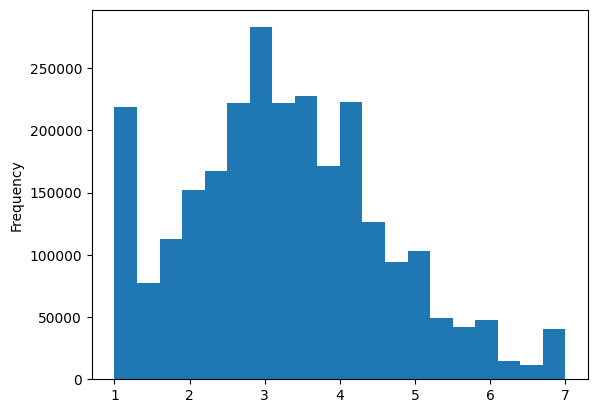

In [21]:
_df.sum(axis=1).clip(0, 7).plot.hist(bins=20)

In [22]:
_df_norm = _df.pipe(lambda df: (df - df.mean()) / df.std()).loc[
    :, lambda df: ~df.isna().any()
]

In [23]:
from sklearn.decomposition import PCA

In [24]:
pca = PCA(7)

In [25]:
x_r = pca.fit(_df_norm.values).transform(_df_norm.values)

In [26]:
def to_entropy(x):
    probs = x / x.sum(axis=1).reshape(-1, 1)
    return -(probs * np.log(probs)).sum(axis=1)

In [27]:
_df_entropies = pd.Series(to_entropy(x_r**2), index=_df.index)

<Axes: ylabel='Frequency'>

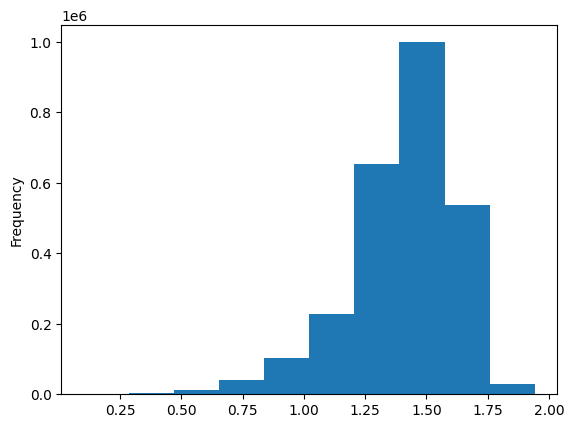

In [28]:
_df_entropies.plot.hist()

In [36]:
ix_names = (
    list(exdf.values())[6]
    .iloc[:, :2]
    .dropna()
    .iloc[1:, :]
    .pipe(lambda df: pd.Series(df.iloc[:, 1].values, index=df.iloc[:, 0].values))
    .to_dict()
)

In [40]:
corrs = {
    ix_names[int(cat)]: _df.loc[:, [cat]]
    .assign(entropy=_df_entropies)
    .corr()
    .iloc[0, 1]
    for cat in tqdm(_df.columns)
}

  0%|          | 0/333 [00:00<?, ?it/s]

In [48]:
_df.shape[0] / 1e6

2.607047

In [50]:
corr_prez = pd.Series(corrs).dropna().sort_values()

In [58]:
for _c, _s in corr_prez.groupby(pd.qcut(corr_prez, 5), observed=True):
    print(_s.rename("corr").to_markdown())

|                                                      |       corr |
|:-----------------------------------------------------|-----------:|
| General Materials Science                            | -0.458188  |
| Mechanics of Materials                               | -0.368744  |
| Condensed Matter Physics                             | -0.334901  |
| Mechanical Engineering                               | -0.324556  |
| Materials Chemistry                                  | -0.284441  |
| Surfaces, Coatings and Films                         | -0.269118  |
| Electronic, Optical and Magnetic Materials           | -0.267966  |
| Metals and Alloys                                    | -0.247276  |
| Ceramics and Composites                              | -0.233908  |
| General Engineering                                  | -0.233877  |
| Surfaces and Interfaces                              | -0.186581  |
| Electrochemistry                                     | -0.181026  |
| Fluid Flow and Tra

<Axes: ylabel='Frequency'>

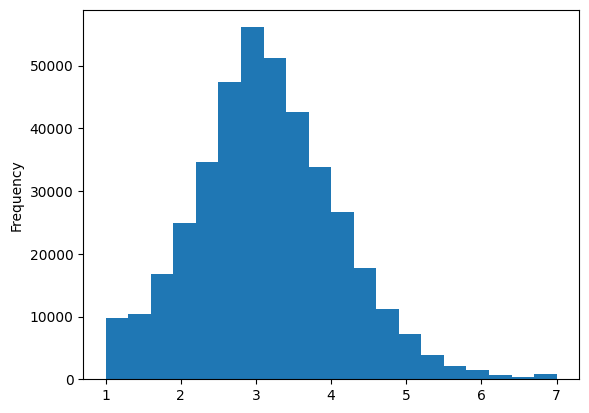

In [139]:
(
    pd.read_csv(next(step2_dir.iterdir()), nrows=400_000)
    .set_index("work_id")
    .sum(axis=1)
    .clip(0, 7)
    .plot.hist(bins=20)
)